In [2]:
import sys

sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

import config
from gbfs import get_feed_urls, parse_station_info

trips = pd.read_parquet(config.PROCESSED_DATA_DIR / "trips_hourly")
weather = pd.read_parquet(config.PROCESSED_DATA_DIR / "weather_hourly.parquet")

# Add up all stations into one row per hour for the whole city, and attach the weather
city = trips.groupby("hour")[["departures", "arrivals"]].sum().reset_index()
city = city.merge(weather, on="hour", how="left")
city["local_time"] = city["hour"].dt.tz_convert(config.TIMEZONE)
city["hour_of_day"] = city["local_time"].dt.hour
city["weekday"] = city["local_time"].dt.dayofweek < 5  # Monday=0 ... Friday=4

print(f"{len(trips):,} station-hours, {city['departures'].sum():,} trips")
print(f"{len(city):,} hours, {city['temperature_2m'].isna().sum()} without weather")

13,061,633 station-hours, 50,439,348 trips
9,483 hours, 12 without weather


/var/folders/9x/7k8dnhzd6ss4y0phbc4fqk9w0000gn/T/ipykernel_16829/3075591405.py:21: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  city["weekday"] = city["local_time"].dt.dayofweek < 5  # Monday=0 ... Friday=4


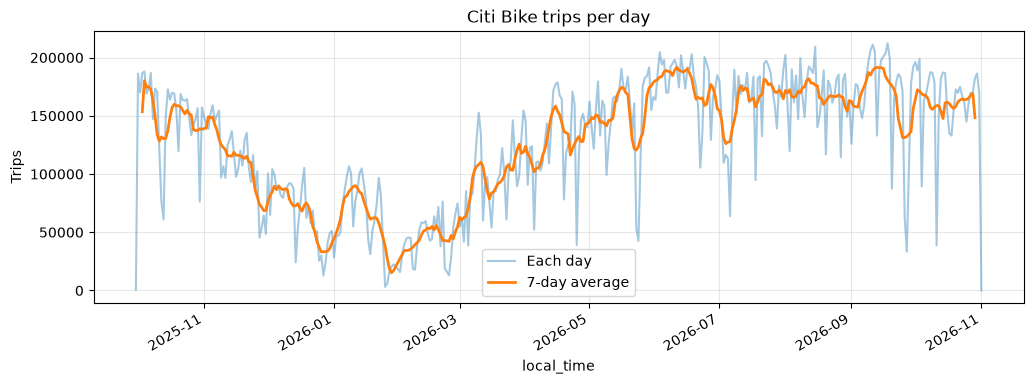

In [3]:
daily = city.groupby(city["local_time"].dt.normalize())["departures"].sum()

ax = daily.plot(figsize=(12, 4), alpha=0.4, label="Each day")
daily.rolling(7, center=True).mean().plot(ax=ax, linewidth=2, label="7-day average")
ax.set_title("Citi Bike trips per day")
ax.set_ylabel("Trips")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

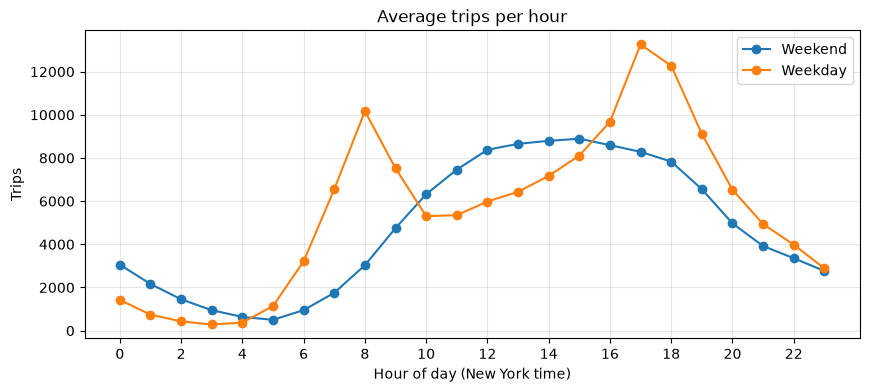

In [4]:
profile = city.groupby(["weekday", "hour_of_day"])["departures"].mean().unstack(0)
profile.columns = ["Weekend", "Weekday"]

ax = profile.plot(figsize=(10, 4), marker="o")
ax.set_title("Average trips per hour")
ax.set_xlabel("Hour of day (New York time)")
ax.set_ylabel("Trips")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.show()

On weekdays from 7 AM to 9 PM, rain or snow cuts trips by about 56%


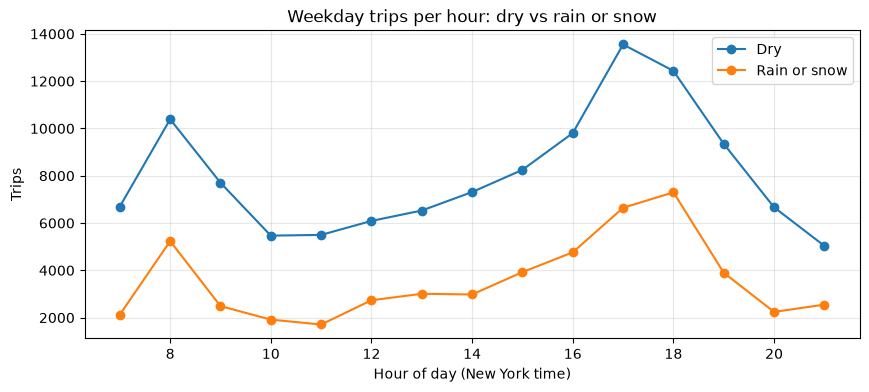

In [5]:
daytime = city[city["weekday"] & city["hour_of_day"].between(7, 21)].copy()
daytime["rainy"] = daytime["precipitation"] > 0

by_rain = daytime.groupby(["hour_of_day", "rainy"])["departures"].mean().unstack()
by_rain.columns = ["Dry", "Rain or snow"]

drop = 1 - by_rain["Rain or snow"].sum() / by_rain["Dry"].sum()
print(f"On weekdays from 7 AM to 9 PM, rain or snow cuts trips by about {drop:.0%}")

ax = by_rain.plot(figsize=(10, 4), marker="o")
ax.set_title("Weekday trips per hour: dry vs rain or snow")
ax.set_xlabel("Hour of day (New York time)")
ax.set_ylabel("Trips")
ax.grid(alpha=0.3)
plt.show()

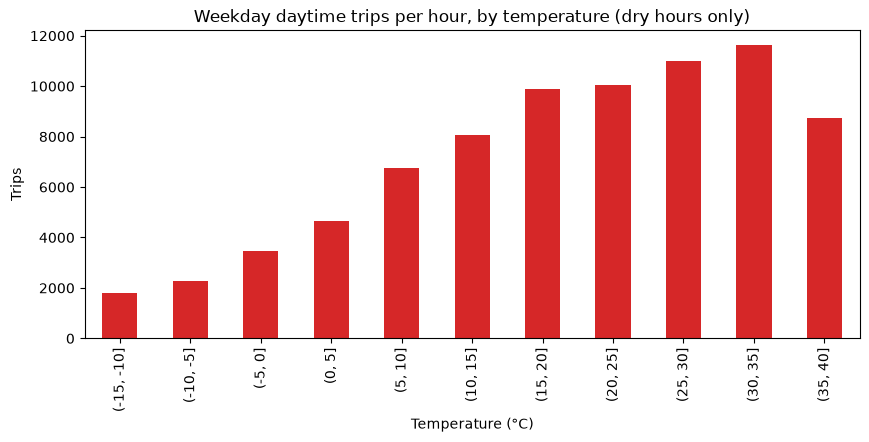

In [6]:
dry = daytime[~daytime["rainy"]].copy()
dry["temperature_band"] = pd.cut(dry["temperature_2m"], bins=range(-20, 45, 5))
by_temperature = dry.groupby("temperature_band", observed=True)["departures"].mean()

ax = by_temperature.plot.bar(figsize=(10, 4), color="tab:red")
ax.set_title("Weekday daytime trips per hour, by temperature (dry hours only)")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Trips")
plt.show()

In [7]:
local = trips["hour"].dt.tz_convert(config.TIMEZONE)
weekday_trips = trips[local.dt.dayofweek < 5].assign(hour_of_day=local.dt.hour)

by_station = weekday_trips.groupby(["station_id", "hour_of_day"])[["departures", "arrivals"]].sum()
totals = by_station.groupby("station_id").sum()
busy = totals[(totals["departures"] + totals["arrivals"]) >= 1000].index

# One row per station: its departures and arrivals in each hour of the day (48 numbers)
profiles = by_station.loc[busy].unstack(fill_value=0)

# Turn counts into shares of the station's own trips, so a huge station and a
# small one with the same rhythm look the same
shares = profiles.div(profiles.sum(axis=1), axis=0)
print(f"{len(shares):,} stations with at least 1,000 weekday trips")

/var/folders/9x/7k8dnhzd6ss4y0phbc4fqk9w0000gn/T/ipykernel_16829/1765112806.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  weekday_trips = trips[local.dt.dayofweek < 5].assign(hour_of_day=local.dt.hour)


2,393 stations with at least 1,000 weekday trips


In [8]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
station_type = pd.Series(kmeans.fit_predict(shares.to_numpy()), index=shares.index, name="station_type")
station_type.value_counts().sort_index()

station_type
0     917
1    1029
2      60
3     387
Name: count, dtype: int64

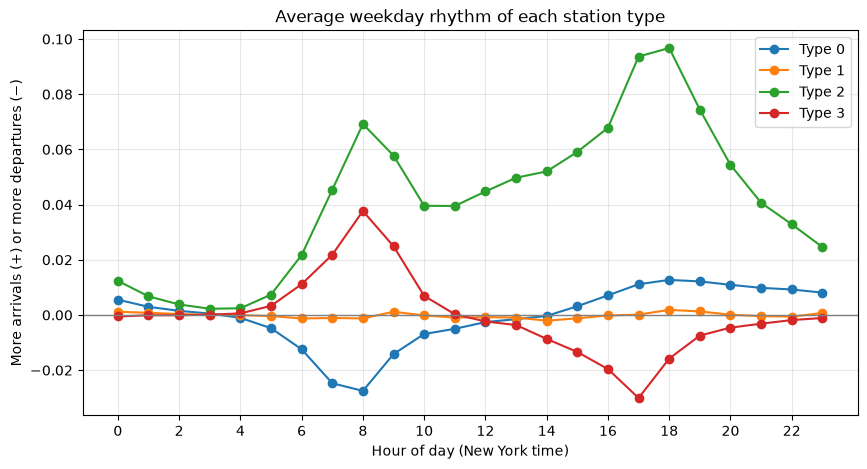

In [9]:
net = shares["arrivals"] - shares["departures"]
net_by_type = net.groupby(station_type).mean().T
net_by_type.columns = [f"Type {number}" for number in net_by_type.columns]

ax = net_by_type.plot(figsize=(10, 5), marker="o")
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("Average weekday rhythm of each station type")
ax.set_xlabel("Hour of day (New York time)")
ax.set_ylabel("More arrivals (+) or more departures (−)")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.show()

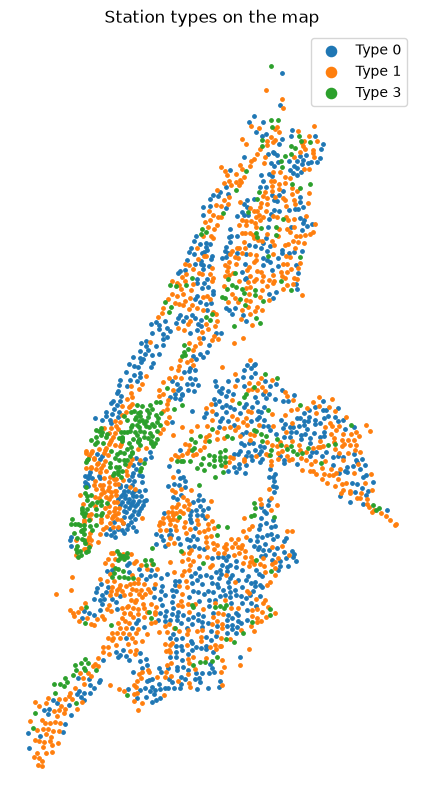

In [10]:
# Station locations, from the live feed (trip files use the stations' short names)
feed_urls = get_feed_urls(requests.get(config.GBFS_URL, timeout=20).json())
info_json = requests.get(feed_urls["station_information"], timeout=20).json()
info = parse_station_info(info_json, pd.Timestamp.now(tz="UTC"))
locations = info.dropna(subset=["short_name"]).set_index("short_name")[["lat", "lon"]]

mapped = locations.join(station_type, how="inner")

fig, ax = plt.subplots(figsize=(8, 10))
for type_number, group in mapped.groupby("station_type"):
    ax.scatter(group["lon"], group["lat"], s=6, label=f"Type {type_number}")
ax.set_title("Station types on the map")
ax.set_aspect(1.32)
ax.axis("off")
ax.legend(markerscale=3)
plt.show()

In [11]:
type_2 = station_type[station_type == 2].index
in_live_feed = locations.index.isin(type_2).sum()
print(f"{len(type_2)} Type 2 stations, {in_live_feed} of them in the live feed")

summary = totals.loc[type_2].copy()
summary["arrivals_per_departure"] = summary["arrivals"] / summary["departures"].clip(lower=1)
summary.sort_values("arrivals", ascending=False).head(15)

60 Type 2 stations, 0 of them in the live feed


,departures,arrivals,arrivals_per_departure
station_id,,,
5980.1,8,34078,4259.750000
6098.1,5,23591,4718.200000
5343.1,6,20515,3419.166667
5669.1,5,17629,3525.800000
6723.1,5,16846,3369.200000
5379.1,7,15474,2210.571429
6364.1,0,15001,15001.000000
7154.1,2,14748,7374.000000
5997.1,0,14739,14739.000000


In [12]:
for short_id in ["5980.1", "6098.1", "6364.1"]:
    twin = short_id + "0"
    in_feed = twin in locations.index
    counts = totals.loc[twin].to_dict() if twin in totals.index else "no trips"
    print(f"{short_id} -> {twin}: in live feed: {in_feed}, weekday trips: {counts}")

5980.1 -> 5980.10: in live feed: True, weekday trips: {'departures': 113336, 'arrivals': 79611}
6098.1 -> 6098.10: in live feed: True, weekday trips: {'departures': 94594, 'arrivals': 70658}
6364.1 -> 6364.10: in live feed: True, weekday trips: {'departures': 65991, 'arrivals': 50357}


In [13]:
for short_id in ["5980.1", "6098.1", "6364.1"]:
    twin = short_id + "0"
    in_feed = twin in locations.index
    counts = totals.loc[twin].to_dict() if twin in totals.index else "no trips"
    print(f"{short_id} -> {twin}: in live feed: {in_feed}, weekday trips: {counts}")

5980.1 -> 5980.10: in live feed: True, weekday trips: {'departures': 113336, 'arrivals': 79611}
6098.1 -> 6098.10: in live feed: True, weekday trips: {'departures': 94594, 'arrivals': 70658}
6364.1 -> 6364.10: in live feed: True, weekday trips: {'departures': 65991, 'arrivals': 50357}
